In [ ]:
# Upgrade pip and setuptools to prevent metadata generation errors
!pip install --upgrade pip setuptools

# BiLSTM-CRF pour la NER (Français / SunuNER)

Modèle neuronal BiLSTM + couche CRF (PyTorch, `pytorch-crf`), avec embeddings de mots entraînés depuis le corpus.

**Corpus** : `Corpus.conll` — 1309 phrases annotées en français (Label Studio → CoNLL, schéma BIO)
Entités : `PER`, `LOC`, `ORG`, `MISC`

Ce notebook est structuré en 6 sections :
1. Importation des bibliothèques
2. Variables, montage de Google Drive et chargement du corpus
3. Split Train / Validation / Test
4. Entraînement du modèle
5. Évaluation (Précision, Rappel, F1, ...)
6. Matrice de confusion


## 1. Importation des bibliothèques

In [1]:
!pip -q install pytorch-crf seqeval

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchcrf import CRF

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from seqeval.metrics import classification_report as seqeval_report
from seqeval.metrics import precision_score, recall_score, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
Device : cuda


## 2. Variables, montage de Google Drive et chargement du corpus annoté

In [2]:
# --- Montage de Google Drive (Colab) ---
from google.colab import drive
drive.mount('/content/drive')

# --- Variables globales ---
DRIVE_ROOT = "/content/drive/MyDrive/Colab Notebooks/S4"       # dossier racine du projet sur Drive (à adapter)
CORPUS_PATH = f"{DRIVE_ROOT}/sununer_corpus.conll"         # fichier CoNLL issu de Label Studio
RANDOM_SEED = 42

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15

import os
assert os.path.exists(CORPUS_PATH), f"Corpus introuvable : {CORPUS_PATH} — vérifier le chemin sur Drive."
print("Corpus trouvé :", CORPUS_PATH)


Mounted at /content/drive
Corpus trouvé : /content/drive/MyDrive/Colab Notebooks/S4/sununer_corpus.conll


In [3]:
# --- Chargement du corpus CoNLL (format BIO : "token\tTAG", phrases séparées par une ligne vide) ---
def load_conll(path):
    """Charge un fichier CoNLL et renvoie une liste de phrases.
    Chaque phrase est une liste de tuples (token, tag)."""
    sentences = []
    current = []

    # Define valid BIO tags based on the specified entity types
    entity_types = {'PER', 'LOC', 'ORG', 'MISC'}
    valid_tags = {'O'}
    for etype in entity_types:
        valid_tags.add(f'B-{etype}')
        valid_tags.add(f'I-{etype}')

    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if line.strip() == "":
                if current:
                    sentences.append(current)
                    current = []
                continue
            # tolère "token tag" ou "token\ttag"
            parts = line.split() if "\t" not in line else line.split("\t")
            if len(parts) < 2:
                continue
            token, tag = parts[0], parts[-1]

            # Validate the tag
            if tag not in valid_tags:
                # If the tag is invalid, skip this token and continue to the next line.
                # This effectively removes malformed entries from the sentences.
                continue

            current.append((token, tag))
    if current:
        sentences.append(current)
    return sentences

sentences = load_conll(CORPUS_PATH)
print(f"Nombre de phrases chargées : {len(sentences)}")
print("Exemple de phrase :", sentences[0][:10])

# Liste des étiquettes présentes dans le corpus
all_tags = sorted({tag for sent in sentences for _, tag in sent})
print("Étiquettes (BIO) présentes :", all_tags)

Nombre de phrases chargées : 1309
Exemple de phrase : [('Macky', 'B-PER'), ('Sall', 'I-PER'), ('à', 'O'), ('Dakar', 'B-LOC'), (':', 'O'), ('La', 'O'), ('date', 'O'), ('de', 'O'), ('sa', 'O'), ('rencontre', 'O')]
Étiquettes (BIO) présentes : ['B-LOC', 'B-MISC', 'B-ORG', 'B-PER', 'I-LOC', 'I-MISC', 'I-ORG', 'I-PER', 'O']


In [4]:
## 3. Split Train / Validation / Test
from sklearn.model_selection import train_test_split

train_sents, temp_sents = train_test_split(
    sentences, test_size=(1 - TRAIN_RATIO), random_state=RANDOM_SEED
)
val_sents, test_sents = train_test_split(
    temp_sents, test_size=TEST_RATIO / (TEST_RATIO + VAL_RATIO), random_state=RANDOM_SEED
)

print(f"Train : {len(train_sents)} phrases")
print(f"Validation : {len(val_sents)} phrases")
print(f"Test : {len(test_sents)} phrases")


Train : 916 phrases
Validation : 196 phrases
Test : 197 phrases


## 4. Entraînement du modèle

Taille du vocabulaire : 4590
Nombre d'étiquettes : 10
Epoch 01/18 - train_loss: 27.2488 - val_loss: 9.0404
Epoch 02/18 - train_loss: 10.1111 - val_loss: 7.4215
Epoch 03/18 - train_loss: 8.2240 - val_loss: 6.0439
Epoch 04/18 - train_loss: 6.5987 - val_loss: 4.6635
Epoch 05/18 - train_loss: 5.2505 - val_loss: 3.7838
Epoch 06/18 - train_loss: 4.1301 - val_loss: 3.1949
Epoch 07/18 - train_loss: 3.2335 - val_loss: 2.8060
Epoch 08/18 - train_loss: 2.5878 - val_loss: 2.4382
Epoch 09/18 - train_loss: 2.0520 - val_loss: 2.1607
Epoch 10/18 - train_loss: 1.6324 - val_loss: 2.0175
Epoch 11/18 - train_loss: 1.3003 - val_loss: 1.8538
Epoch 12/18 - train_loss: 1.0369 - val_loss: 1.8111
Epoch 13/18 - train_loss: 0.8221 - val_loss: 1.7732
Epoch 14/18 - train_loss: 0.6564 - val_loss: 1.7993
Epoch 15/18 - train_loss: 0.5371 - val_loss: 1.6616
Epoch 16/18 - train_loss: 0.4155 - val_loss: 1.7075
Epoch 17/18 - train_loss: 0.3336 - val_loss: 1.6781
Epoch 18/18 - train_loss: 0.2655 - val_loss: 1.7577


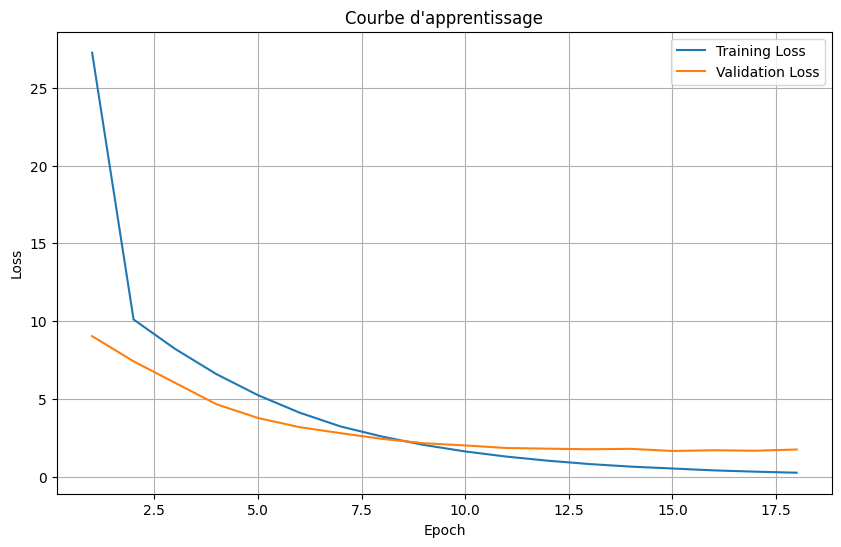

In [9]:
# --- Construction des vocabulaires ---
PAD, UNK = "<PAD>", "<UNK>"

word_counter = {}
for sent in train_sents:
    for tok, _ in sent:
        word_counter[tok.lower()] = word_counter.get(tok.lower(), 0) + 1

word2idx = {PAD: 0, UNK: 1}
for w in word_counter:
    word2idx[w] = len(word2idx)

tag2idx = {PAD: 0}
for tag in all_tags:
    if tag not in tag2idx:
        tag2idx[tag] = len(tag2idx)
idx2tag = {i: t for t, i in tag2idx.items()}

VOCAB_SIZE = len(word2idx)
NUM_TAGS = len(tag2idx)
EMBED_DIM = 100
HIDDEN_DIM = 128
BATCH_SIZE = 16
NUM_EPOCHS = 18
LEARNING_RATE = 1e-3

print("Taille du vocabulaire :", VOCAB_SIZE)
print("Nombre d'étiquettes :", NUM_TAGS)

# --- Dataset PyTorch ---
class NERDataset(Dataset):
    def __init__(self, sentences, word2idx, tag2idx):
        self.sentences = sentences
        self.word2idx = word2idx
        self.tag2idx = tag2idx

    def __len__(self):
        return len(self.sentences)

    def __getitem__(self, idx):
        sent = self.sentences[idx]
        words = [self.word2idx.get(tok.lower(), self.word2idx[UNK]) for tok, _ in sent]
        tags = [self.tag2idx[tag] for _, tag in sent]
        return torch.tensor(words, dtype=torch.long), torch.tensor(tags, dtype=torch.long)

def collate_fn(batch):
    words, tags = zip(*batch)
    lengths = torch.tensor([len(w) for w in words])
    max_len = lengths.max().item()
    words_padded = torch.zeros(len(batch), max_len, dtype=torch.long)
    tags_padded = torch.zeros(len(batch), max_len, dtype=torch.long)
    mask = torch.zeros(len(batch), max_len, dtype=torch.bool)
    for i, (w, t) in enumerate(zip(words, tags)):
        words_padded[i, :len(w)] = w
        tags_padded[i, :len(t)] = t
        mask[i, :len(w)] = True
    return words_padded, tags_padded, mask, lengths

train_ds = NERDataset(train_sents, word2idx, tag2idx)
val_ds = NERDataset(val_sents, word2idx, tag2idx)
test_ds = NERDataset(test_sents, word2idx, tag2idx)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

# --- Modèle BiLSTM-CRF ---
class BiLSTM_CRF(nn.Module):
    def __init__(self, vocab_size, tagset_size, embed_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim // 2, num_layers=1,
                             bidirectional=True, batch_first=True)
        self.hidden2tag = nn.Linear(hidden_dim, tagset_size)
        self.crf = CRF(tagset_size, batch_first=True)

    def _get_emissions(self, x):
        embeds = self.embedding(x)
        lstm_out, _ = self.lstm(embeds)
        return self.hidden2tag(lstm_out)

    def forward(self, x, tags, mask):
        emissions = self._get_emissions(x)
        loss = -self.crf(emissions, tags, mask=mask, reduction='mean')
        return loss

    def predict(self, x, mask):
        emissions = self._get_emissions(x)
        return self.crf.decode(emissions, mask=mask)

model = BiLSTM_CRF(VOCAB_SIZE, NUM_TAGS, EMBED_DIM, HIDDEN_DIM).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# --- Boucle d'entraînement ---
train_losses_history = []
val_losses_history = []

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for words, tags, mask, _ in train_loader:
        words, tags, mask = words.to(device), tags.to(device), mask.to(device)
        optimizer.zero_grad()
        loss = model(words, tags, mask)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for words, tags, mask, _ in val_loader:
            words, tags, mask = words.to(device), tags.to(device), mask.to(device)
            val_loss += model(words, tags, mask).item()

    avg_train_loss = total_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)
    train_losses_history.append(avg_train_loss)
    val_losses_history.append(avg_val_loss)

    print(f"Epoch {epoch:02d}/{NUM_EPOCHS} - train_loss: {avg_train_loss:.4f} "
          f"- val_loss: {avg_val_loss:.4f}")

# --- Plotting the Learning Curve ---
# Ensure matplotlib.pyplot is imported, although it should be from cell 4dd22ef2
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(range(1, NUM_EPOCHS + 1), train_losses_history, label='Training Loss')
plt.plot(range(1, NUM_EPOCHS + 1), val_losses_history, label='Validation Loss')
plt.title('Courbe d\'apprentissage')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
#plt.savefig('courbe_apprentissage.png')
plt.show()

## 5. Évaluation (Précision, Rappel, F1, ...)

In [10]:

def predict_dataset(loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for words, tags, mask, lengths in loader:
            words, mask_dev = words.to(device), mask.to(device)
            preds = model.predict(words, mask_dev)

            for i, length in enumerate(lengths):
                true_seq = tags[i, :length].tolist()
                pred_seq = preds[i]

                y_true.append([idx2tag[t] for t in true_seq])
                y_pred.append([idx2tag[t] for t in pred_seq])

    return y_true, y_pred


# ==================== ÉVALUATION TRAIN ====================
y_train_true, y_train_pred = predict_dataset(train_loader)

print("=== Évaluation sur TRAIN ===")
print(seqeval_report(y_train_true, y_train_pred, digits=4))


# ==================== ÉVALUATION VALIDATION ====================
y_val_true, y_val_pred = predict_dataset(val_loader)

print("=== Évaluation sur VALIDATION ===")
print(seqeval_report(y_val_true, y_val_pred, digits=4))


# ==================== ÉVALUATION TEST ====================
y_test_true, y_test_pred = predict_dataset(test_loader)

print("=== Évaluation sur TEST ===")
print(seqeval_report(y_test_true, y_test_pred, digits=4))

print(f"Précision (test) : {precision_score(y_test_true, y_test_pred):.4f}")
print(f"Rappel (test)    : {recall_score(y_test_true, y_test_pred):.4f}")
print(f"F1-score (test)  : {f1_score(y_test_true, y_test_pred):.4f}")

=== Évaluation sur TRAIN ===
              precision    recall  f1-score   support

         LOC     0.9960    1.0000    0.9980       249
        MISC     0.9826    0.9826    0.9826       115
         ORG     0.9924    0.9924    0.9924       264
         PER     1.0000    0.9975    0.9987       394

   micro avg     0.9951    0.9951    0.9951      1022
   macro avg     0.9928    0.9931    0.9929      1022
weighted avg     0.9951    0.9951    0.9951      1022

=== Évaluation sur VALIDATION ===
              precision    recall  f1-score   support

         LOC     0.9024    0.7400    0.8132        50
        MISC     0.8824    0.7143    0.7895        21
         ORG     0.8780    0.6545    0.7500        55
         PER     0.8714    0.8026    0.8356        76

   micro avg     0.8817    0.7376    0.8032       202
   macro avg     0.8836    0.7279    0.7971       202
weighted avg     0.8820    0.7376    0.8020       202

=== Évaluation sur TEST ===
              precision    recall  f1-s

## 6. Matrice de confusion

In [11]:
y_test_flat = [tag for seq in y_test_true for tag in seq]
y_pred_flat = [tag for seq in y_test_pred for tag in seq]


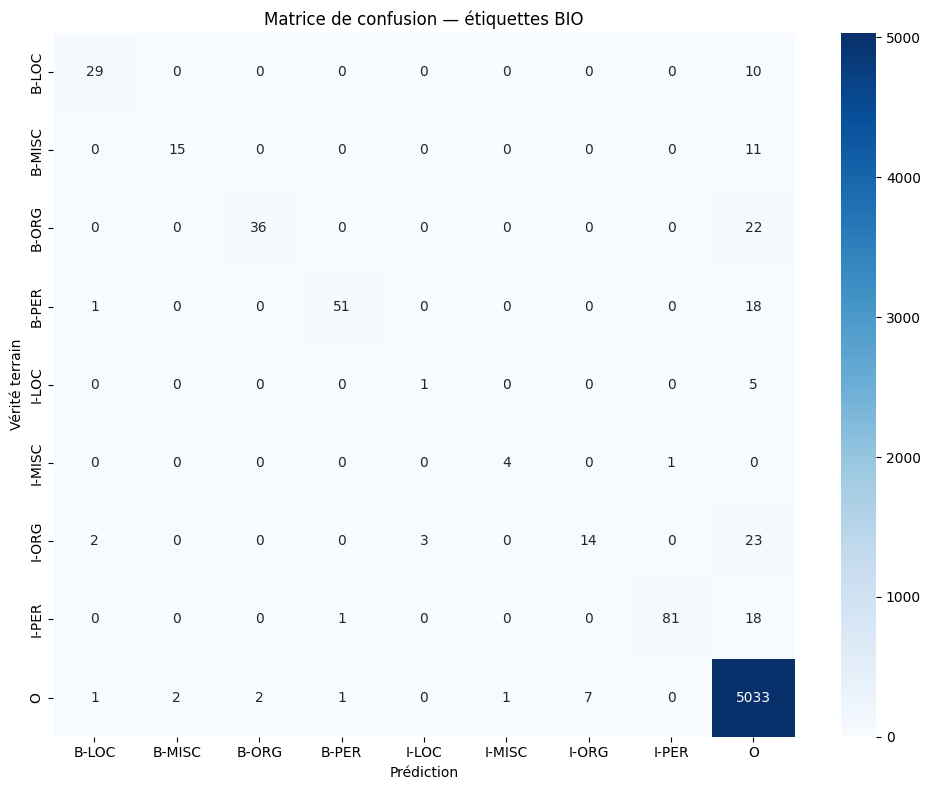

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels_sorted = sorted(all_tags)
cm = confusion_matrix(y_test_flat, y_pred_flat, labels=labels_sorted)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_sorted, yticklabels=labels_sorted)
plt.xlabel("Prédiction")
plt.ylabel("Vérité terrain")
plt.title("Matrice de confusion — étiquettes BIO")
plt.tight_layout()
plt.show()
#plt.savefig('confusion_matrix_bilstm.png')
